# 06 · Análisis II: propiedades físicas de planetas pequeños

**Sección de la tesis:** 6.3 (6.3.1 relación masa–radio–irradiación; 6.3.2 contribución de las propiedades estelares).

**Pregunta.** Entre planetas de radio e irradiación comparables, ¿la masa y la metalicidad de la estrella se relacionan con la masa planetaria que queda sin explicar?

**Muestra.** Planetas de 1 a 4 $R_\oplus$ con masa verdadera (`pl_bmassprov = Mass`), radio medido (observados en tránsito), sin límites en masa ni radio, con flujo incidente, masa estelar y metalicidad. Se excluyen los planetas con una masa mayor que la de un planeta de hierro puro del mismo radio (Zeng et al. 2016), porque no son físicamente posibles.

**Modelos** (regresión lineal; respuesta `log_Mp` = $\log_{10} M_p$; $s(\cdot)$ = *spline* cúbico; errores agrupados por estrella):

| Modelo | Predictores |
|---|---|
| M0 | `s(log_Rp)` |
| M1 (base) | `s(log_Rp) + logF_z` |
| M2 (estelar) | `s(log_Rp) + logF_z + st_mass_z + st_met_z` |

**Salidas:** tablas A2-T1 a A2-T6; figuras A2-F1 y A2-F2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

## 1. Muestra

In [2]:
df = cargar_catalogo()
a2, cortes = muestra_analisis_II(df)
ESTANDARIZAR = ["logF", "st_mass", "st_met"]
a2 = estandarizar(a2, ESTANDARIZAR)
grupos = a2["hostname"]
composicion = a2["clase_radio"].value_counts().reindex(CLASES_RADIO[:3])
print(f"Planetas: {len(a2)} | estrellas: {grupos.nunique()}")

tabla_cortes = guardar_tabla(
    cortes, "A2-T1", "cortes_de_la_muestra",
    titulo="Análisis II: construcción de la muestra. Número de planetas y de estrellas después de cada corte sucesivo sobre el catálogo limpio.",
    seccion="6.3.1",
    nota="Composición final por régimen de radio: " + ", ".join(
        f"{ETIQUETA_CLASE[c].lower()} {n}" for c, n in composicion.items()) + ".")
tabla_cortes

Planetas: 535 | estrellas: 365
Tabla A2-T1 guardada: tablas/A2-T1_cortes_de_la_muestra.csv


,corte,N_planetas,N_estrellas
0,Masa y radio disponibles,6199,4676
1,Sin límites superiores o inferiores,6013,4598
2,Solo masa verdadera (pl_bmassprov = Mass),2165,1793
3,Radio medido (planeta observado en tránsito),1504,1224
4,Con masa estelar,1504,1224
5,Con metalicidad,1488,1208
6,Con flujo incidente calculado,1488,1208
7,Planetas pequeños (1 < Rp < 4),574,385
8,Masa no mayor que la de un planeta de hierro p...,535,365


## 2. Modelos (secciones 6.3.1 y 6.3.2)

El *spline* de `log_Rp` tiene 4 grados de libertad (un nudo interior en la mediana). M0 → M1 evalúa si el flujo incidente añade información a la relación masa–radio; M1 → M2, que es la comparación central, evalúa la contribución de la estrella.

In [3]:
def X_masa_radio(d, extras, nudos):
    X = base_spline(d["log_Rp"], nudos, "sR")
    X.insert(0, "const", 1.0)
    for columna in extras:
        X[columna] = d[columna].to_numpy()
    return X

EXTRAS = {"M0": [], "M1": ["logF_z"], "M2": ["logF_z", "st_mass_z", "st_met_z"]}
formulas = {"M0": "s(log_Rp)", "M1": "s(log_Rp) + logF_z", "M2": "s(log_Rp) + logF_z + st_mass_z + st_met_z"}
nudos = nudos_spline(a2["log_Rp"], gl=4)
ajustes = {nombre: ajustar_lineal(a2["log_Mp"], X_masa_radio(a2, extras, nudos), grupos, nombre)
           for nombre, extras in EXTRAS.items()}
M0, M1, M2 = ajustes["M0"], ajustes["M1"], ajustes["M2"]

comparacion = comparar_modelos(ajustes, formulas, referencia="M1", deltas=["R2", "AIC", "RMSE", "MAE"])
tabla_comparacion = guardar_tabla(
    comparacion.rename(columns={"N": "N_planetas"}), "A2-T2", "comparacion_modelos_masa_radio",
    titulo="Análisis II: comparación de los modelos de la masa planetaria en la muestra de ajuste. Diferencias respecto al modelo base M1.",
    seccion="6.3.2",
    nota=f"{len(a2)} planetas alrededor de {grupos.nunique()} estrellas. s() denota un spline cúbico. RMSE y MAE en dex.",
    formatos={"delta_AIC": "{:+.1f}", "AIC": "{:.1f}", "BIC": "{:.1f}", "delta_R2": "{:+.4f}", "delta_RMSE": "{:+.4f}", "delta_MAE": "{:+.4f}"})
tabla_comparacion

Tabla A2-T2 guardada: tablas/A2-T2_comparacion_modelos_masa_radio.csv


,modelo,predictores,N_planetas,R2,R2_ajustado,AIC,BIC,RMSE,MAE,delta_R2,delta_AIC,delta_RMSE,delta_MAE
0,M0,s(log_Rp),535,0.4823,0.4784,126.8852,148.2966,0.2699,0.1938,-0.0184,17.3828,0.0048,0.0031
1,M1,s(log_Rp) + logF_z,535,0.5007,0.4960,109.5025,135.1961,0.2651,0.1907,0.0000,0.0000,0.0000,0.0000
2,M2,s(log_Rp) + logF_z + st_mass_z + st_met_z,535,0.5056,0.4990,108.2638,142.5220,0.2638,0.1900,0.0049,-1.2386,-0.0013,-0.0007


In [4]:
print(pd.DataFrame([razon_verosimilitud(M0, M1), razon_verosimilitud(M1, M2)]).round(5).to_string(index=False))

comparacion       LR  gl  valor_p
   M0 vs M1 19.38276   1  0.00001
   M1 vs M2  5.23864   2  0.07285


### Validación cruzada agrupada por estrella

En cada pliegue, los nudos del *spline* y la media y desviación usadas para estandarizar se calculan solo con el conjunto de entrenamiento.

In [5]:
def constructor(extras):
    def construir(ent, pru):
        nudos_ent = nudos_spline(ent["log_Rp"], gl=4)
        ent_z = estandarizar(ent, ESTANDARIZAR)
        pru_z = estandarizar(pru, ESTANDARIZAR, referencia=ent)
        return X_masa_radio(ent_z, extras, nudos_ent), X_masa_radio(pru_z, extras, nudos_ent)
    return construir

pliegues, resumen_vc = validacion_cruzada(a2, "log_Mp", "lineal", {n: constructor(e) for n, e in EXTRAS.items()})
for metrica in ["R2", "RMSE", "MAE"]:
    resumen_vc[f"delta_{metrica}_vc"] = resumen_vc[f"{metrica}_vc_media"] - resumen_vc.loc[1, f"{metrica}_vc_media"]
tabla_vc = guardar_tabla(
    resumen_vc, "A2-T3", "validacion_cruzada",
    titulo="Análisis II: desempeño en validación cruzada de cinco pliegues agrupada por estrella. Diferencias respecto al modelo base M1.",
    seccion="6.3.2", nota="Media y desviación estándar entre pliegues.",
    encabezados={"R2_vc_media": "$R^2$ VC", "R2_vc_desv": "D.E.", "RMSE_vc_media": "RMSE VC", "RMSE_vc_desv": "D.E.",
                 "MAE_vc_media": "MAE VC", "MAE_vc_desv": "D.E.", "delta_R2_vc": r"$\Delta R^2$",
                 "delta_RMSE_vc": r"$\Delta$RMSE", "delta_MAE_vc": r"$\Delta$MAE"},
    formatos={"delta_R2_vc": "{:+.4f}", "delta_RMSE_vc": "{:+.4f}", "delta_MAE_vc": "{:+.4f}"})
guardar_tabla(pliegues, "A2-T6", "validacion_cruzada_por_pliegue",
              titulo="Análisis II: validación cruzada por pliegue.", seccion="6.3.2", destino="anexo",
              encabezados={"N_entrenamiento": r"$N$ entren.", "N_prueba": r"$N$ prueba", "N_estrellas_prueba": r"$N_\star$ prueba"})
tabla_vc

Tabla A2-T3 guardada: tablas/A2-T3_validacion_cruzada.csv
Tabla A2-T6 guardada: tablas/A2-T6_validacion_cruzada_por_pliegue.csv


,modelo,R2_vc_media,R2_vc_desv,RMSE_vc_media,RMSE_vc_desv,MAE_vc_media,MAE_vc_desv,delta_R2_vc,delta_RMSE_vc,delta_MAE_vc
0,M0,0.4700,0.0314,0.2712,0.0270,0.1954,0.0145,-0.0180,0.0047,0.0031
1,M1,0.4879,0.0380,0.2665,0.0271,0.1923,0.0137,0.0000,0.0000,0.0000
2,M2,0.4883,0.0359,0.2668,0.0314,0.1924,0.0166,0.0003,0.0003,0.0001


### Coeficientes

Predictores estandarizados: cada coeficiente es el cambio en $\log_{10} M_p$ (dex) por un aumento de una desviación estándar.

In [6]:
coeficientes = pd.concat([M1.coeficientes(solo=["logF_z"]),
                          M2.coeficientes(solo=["logF_z", "st_mass_z", "st_met_z"])], ignore_index=True)
tabla_coeficientes = guardar_tabla(
    coeficientes, "A2-T4", "coeficientes_modelos_masa_radio",
    titulo="Análisis II: coeficientes estandarizados del flujo incidente, la masa estelar y la metalicidad en los modelos M1 y M2.",
    seccion="6.3.2",
    nota="Cambio en el logaritmo de la masa planetaria (dex) por una desviación estándar del predictor. Errores estándar agrupados por estrella.")
tabla_coeficientes

Tabla A2-T4 guardada: tablas/A2-T4_coeficientes_modelos_masa_radio.csv


,modelo,predictor,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p
0,M1,logF_z,0.0542,0.0109,0.0329,0.0756,6.420000e-07
1,M2,logF_z,0.0364,0.0163,0.0044,0.0685,2.580000e-02
2,M2,st_mass_z,0.0251,0.0201,-0.0142,0.0645,2.100000e-01
3,M2,st_met_z,0.0171,0.0131,-0.0087,0.0429,1.930000e-01


## 3. Figuras

Figura A2-F1 guardada: figuras/A2-F1_diagrama_masa_radio_planetas_pequenos.png y .pdf


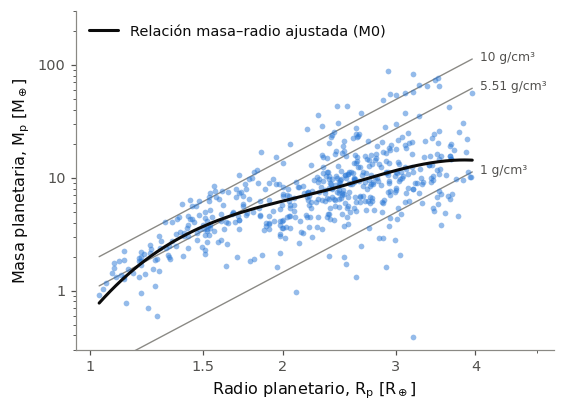

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 4.0))
radios = np.logspace(np.log10(a2["pl_rade"].min()), np.log10(a2["pl_rade"].max()), 200)
for rho in [1.0, RHO_TIERRA, 10.0]:
    ax.plot(radios, rho / RHO_TIERRA * radios ** 3, color=GRIS, linewidth=0.9, zorder=1)
    ax.text(4.06, rho / RHO_TIERRA * 4.0 ** 3, f"{rho:g} g/cm³", fontsize=8, color=TINTA_SECUNDARIA, va="center")
ax.scatter(a2["pl_rade"], a2["pl_bmasse"], s=14, color=COLOR_UNICO, alpha=0.5, linewidths=0, zorder=2)
curva = pd.DataFrame({"log_Rp": np.log10(radios)})
ax.plot(radios, 10 ** M0.predecir(X_masa_radio(curva, [], nudos)), color=TINTA, linewidth=2.0, zorder=3,
        label="Relación masa–radio ajustada (M0)")
eje_log_simple(ax, "xy")
ax.set_xticks([1, 1.5, 2, 3, 4])
ax.set_xlim(0.95, 5.3)
ax.set_ylim(0.3, 300)
ax.set_xlabel(EJE["pl_rade"])
ax.set_ylabel(EJE["pl_bmasse"])
ax.grid(visible=False)
ax.legend(loc="upper left")
guardar_figura(fig, "A2-F1", "diagrama_masa_radio_planetas_pequenos",
               titulo=("Diagrama masa-radio de la muestra del análisis II. La curva negra es la relación ajustada con el spline "
                       "del modelo M0; las líneas grises son curvas de densidad constante."),
               seccion="6.3.1", nota=f"N = {len(a2)} planetas de 1-4 R_Tierra con masa verdadera.")
plt.show()

Tabla A2-T5 guardada: tablas/A2-T5_residuos_del_modelo_base.csv
Figura A2-F2 guardada: figuras/A2-F2_efectos_estelares_sobre_la_masa.png y .pdf


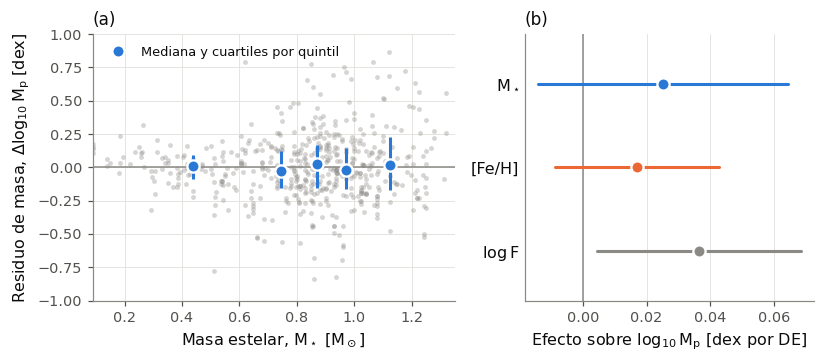

,variable,N,mediana,Q1,Q3,IQR,minimo,maximo
0,residuo_M1,535,-0.0064,-0.1452,0.1374,0.2826,-1.5492,0.866


In [8]:
a2["residuo_M1"] = M1.residuos
tabla_residuos = guardar_tabla(
    descriptiva(a2, ["residuo_M1"]), "A2-T5", "residuos_del_modelo_base",
    titulo="Análisis II: distribución de los residuos de masa (dex) respecto al modelo base M1.",
    seccion="6.3.2", destino="anexo")

fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = ejes[0]
ax.scatter(a2["st_mass"], a2["residuo_M1"], s=10, color=GRIS, alpha=0.35, linewidths=0, zorder=1)
a2["quintil_st_mass"] = pd.qcut(a2["st_mass"], 5)
medianas = a2.groupby("quintil_st_mass", observed=True).agg(x=("st_mass", "median"), y=("residuo_M1", "median"),
                                                           q1=("residuo_M1", lambda v: v.quantile(0.25)),
                                                           q3=("residuo_M1", lambda v: v.quantile(0.75)))
ax.vlines(medianas["x"], medianas["q1"], medianas["q3"], color=COLOR_MASA_ESTELAR, linewidth=2, zorder=2)
ax.plot(medianas["x"], medianas["y"], "o", color=COLOR_MASA_ESTELAR, markersize=8,
        markeredgecolor="white", markeredgewidth=1.5, zorder=3, label="Mediana y cuartiles por quintil")
linea_referencia(ax, 0.0, eje="y")
ax.set_xlim(a2["st_mass"].quantile(0.005), a2["st_mass"].quantile(0.995))
ax.set_ylim(-1.0, 1.0)
ax.set_xlabel(EJE["st_mass"])
ax.set_ylabel(r"Residuo de masa, $\Delta\log_{10} M_p$ [dex]")
ax.legend(loc="upper left", fontsize=8.5)
etiqueta_panel(ax, "a")

ax = ejes[1]
c = M2.coeficientes(solo=["st_mass_z", "st_met_z", "logF_z"]).set_index("predictor").loc[["st_mass_z", "st_met_z", "logF_z"]]
grafico_efectos(ax, [r"$M_\star$", "[Fe/H]", r"$\log F$"], c["coeficiente"], c["IC95_inf"], c["IC95_sup"],
                        [COLOR_MASA_ESTELAR, COLOR_METALICIDAD, GRIS])
ax.set_xlabel(r"Efecto sobre $\log_{10} M_p$ [dex por DE]")
etiqueta_panel(ax, "b")
fig.tight_layout()
guardar_figura(fig, "A2-F2", "efectos_estelares_sobre_la_masa",
               titulo=("(a) Residuos de masa respecto al modelo base M1 (radio y flujo incidente) en función de la masa estelar; "
                       "los puntos azules son la mediana y los cuartiles en quintiles de masa estelar. (b) Coeficientes "
                       "estandarizados del modelo M2 con intervalos de confianza al 95 %."),
               seccion="6.3.2", nota="El panel (a) omite los residuos fuera de ±1 dex para facilitar la lectura.")
plt.show()
tabla_residuos

## 4. Guardar la muestra con residuos

In [9]:
a2.drop(columns="quintil_st_mass").to_csv(DATOS_PROCESADOS / "A2_muestra_propiedades_fisicas.csv", index=False)

## Lectura de los resultados

- El radio explica una parte de la variación de la masa (M0); la dispersión restante es grande.
- El flujo incidente mejora ligeramente el ajuste (M0 → M1), pero casi nada fuera de muestra.
- Al añadir la estrella (M1 → M2), los intervalos de la masa estelar y de la metalicidad incluyen el cero, y el flujo sigue siendo positivo.
- En validación cruzada M2 no mejora a M1: a radio e irradiación comparables no se detecta asociación con la estrella.
- Con los 39 planetas más densos que el hierro puro sí aparecía un efecto de la masa estelar; ese resultado dependía de ellos.